# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy CV (train): 0.9791 ± 0.0277
Accuracy test:       0.9722
F1 macro test:       0.9710

              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        12
     class_1      0.933     1.000     0.966        14
     class_2      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36



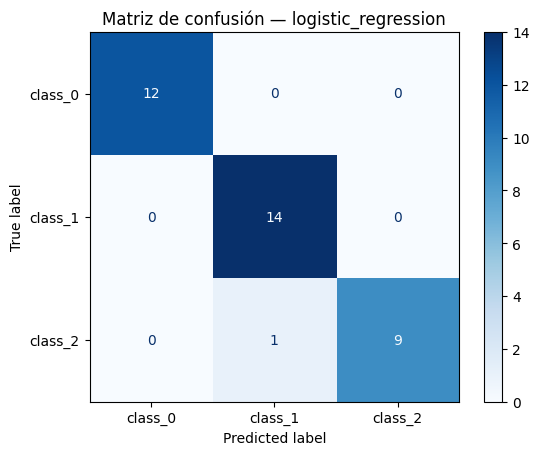

In [4]:
y_pred = model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy CV (train): {training_metadata['cv_accuracy']:.4f} ± {training_metadata['cv_std']:.4f}")
print(f"Accuracy test:       {test_accuracy:.4f}")
print(f"F1 macro test:       {test_f1_macro:.4f}\n")
print(classification_report(y_test, y_pred, target_names=contract["target_names"], digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=contract["target_names"], cmap="Blues"
)
plt.title(f"Matriz de confusión — {training_metadata['champion']}")
plt.show()

**Análisis:**

> - **Coherencia con CV:** el accuracy en test (0.972) cae dentro del rango esperado por validación cruzada (0.979 ± 0.028). El modelo generaliza como se estimó.
> - **Confusiones:** solo hay 1 error en 36 muestras: un vino de la **clase 2 se predijo como clase 1**. La clase 0 se clasifica perfecto. Esto coincide con el EDA: las clases 1 y 2 se parecen más en `proline` (~526 frente a ~623), así que se distinguen sobre todo por `flavanoids` y `color_intensity`.
> - **Sobreajuste:** no hay evidencia relevante. Aunque el accuracy de train es 1.0, el de test es casi igual al de CV. Con solo 36 muestras de test, cada error mueve el accuracy ~2.8 puntos, así que la estimación tiene bastante incertidumbre.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    # Columnas extra se ignoran y el orden se fuerza al del contrato
    X = records[feature_columns]

    output = pd.DataFrame(index=records.index)
    output["prediction"] = model.predict(X)
    probabilities = model.predict_proba(X)
    for i, label in enumerate(model.classes_):
        output[f"proba_{label}"] = probabilities[:, i].round(4)
    return output


# Prueba rápida de la validación del esquema
try:
    predict(X_test.drop(columns=["alcohol"]).head(1))
except ValueError as error:
    print("Validación OK ->", error)

Validación OK -> Faltan columnas requeridas: ['alcohol']


## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
batch_predictions

,prediction,proba_0,proba_1,proba_2
0,0,0.9997,0.0003,0.0000
1,1,0.0071,0.5404,0.4525
2,0,0.9920,0.0077,0.0003
3,1,0.2900,0.7075,0.0026
4,1,0.0330,0.9623,0.0047


## 5. Reporte final

In [7]:
test_metrics = {
    "model": training_metadata["champion"],
    "best_params": training_metadata["best_params"],
    "cv_accuracy": training_metadata["cv_accuracy"],
    "test_accuracy": float(test_accuracy),
    "test_f1_macro": float(test_f1_macro),
    "n_test": int(len(y_test)),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2), encoding="utf-8"
)
test_metrics

{'model': 'logistic_regression',
 'best_params': {'model__C': 1},
 'cv_accuracy': 0.9790640394088669,
 'test_accuracy': 0.9722222222222222,
 'test_f1_macro': 0.9709618874773139,
 'n_test': 36}

In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Regresión logística (`C = 1`) con imputación por mediana + `StandardScaler` |
| Accuracy CV | 0.979 ± 0.028 (5 folds estratificados) |
| Accuracy test | 0.972 (35 de 36 correctas) |
| F1 macro test | 0.971 |
| Clases más confundidas | Clase 2 → clase 1 (1 caso) |
| Principal limitación | Dataset muy pequeño (178 vinos, 36 en test): la métrica es poco precisa y el modelo solo conoce 3 cultivares de una región. Además, algunas predicciones salen con baja confianza (p. ej. 0.54 frente a 0.45 entre las clases 1 y 2). |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.